# 1 - Logistic Regression with a Neural Network Mindset
**Objective:** Implement a single-neuron forecasting model (Logistic Regression architecture) from scratch using vectorized NumPy operations to predict Spanish day-ahead electricity prices (`Price_EUR_MWh`).

First, we import the required libraries for data handling, normalization, numerical computation, and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Set random seed for consistent results
np.random.seed(42)

# 2 - Dataset Loading and Chronological Split
We load `Master_Dataset_Engineered_2023_2025.xlsx` (26,136 hourly observations) and divide it chronologically into:
- **Training Set (2023–2024):** First 17,376 rows (`2023-01-08 00:00` to `2024-12-31 23:00`).
- **Testing Set (2025):** Last 8,760 rows (`2025-01-01 00:00` to `2025-12-31 23:00`).

Column `1` (`Price_EUR_MWh`) is extracted as the target output `y`, and columns `2` to `13` (12 engineered features) are extracted as the input matrix `x`.

In [2]:
# Load the master Excel file
file_path = "C:\ProjecteAIApplications\model_input\Master_Dataset_Engineered_2023_2025.xlsx"
df = pd.read_excel(file_path)

# Verify chronological split index (17,376 rows for 2023-2024; 8,760 rows for 2025)
input_data = df.iloc[:17376].values
input_data_2025 = df.iloc[17376:].values

# Categorizing the data into inputs (x) and outputs (y) for train and test sets
# Column 0: Datetime | Column 1: Price_EUR_MWh (y) | Columns 2 to 13: Input Features (x)
train_set_x_orig = input_data[:, 2:].astype(float)
test_set_x_orig = input_data_2025[:, 2:].astype(float)

train_set_y_orig = input_data[:, 1:2].astype(float)
test_set_y_orig = input_data_2025[:, 1:2].astype(float)

print(f"train_set_x_orig shape: {train_set_x_orig.shape}")
print(f"train_set_y_orig shape: {train_set_y_orig.shape}")
print(f"test_set_x_orig shape:  {test_set_x_orig.shape}")
print(f"test_set_y_orig shape:  {test_set_y_orig.shape}")

train_set_x_orig shape: (17376, 12)
train_set_y_orig shape: (17376, 1)
test_set_x_orig shape:  (8760, 12)
test_set_y_orig shape:  (8760, 1)


# 3 - Feature and Target Normalization
To ensure stable gradient descent convergence and prevent large-magnitude variables (such as `Hydro_Reservoir_MWh`) from dominating the weights, we scale all features and target values to the `(0, 1)` range using `MinMaxScaler`.

We then transpose (`.T`) each array so that its dimensions follow the neural network convention `(n_features, m_samples)`.

In [3]:
# Normalization to range (0, 1)
scaler_x = MinMaxScaler(feature_range=(0, 1))
scaler_y_train = MinMaxScaler(feature_range=(0, 1))
scaler_y_test = MinMaxScaler(feature_range=(0, 1))

train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.fit_transform(test_set_x_orig)

train_set_y_normalized = scaler_y_train.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y_test.fit_transform(test_set_y_orig)

# Transpose arrays so features are in rows and hourly samples are in columns
train_set_x_normalized = train_set_x_normalized.T
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

# Extract dataset dimensions
m_train = train_set_x_normalized.shape[1]
m_test = test_set_x_normalized.shape[1]
n_x = train_set_x_normalized.shape[0]

print(f"Number of training samples (m_train): {m_train}")
print(f"Number of testing samples (m_test):   {m_test}")
print(f"Number of input features (n_x):       {n_x}")
print(f"train_set_x_normalized shape:         {train_set_x_normalized.shape}")
print(f"train_set_y_normalized shape:         {train_set_y_normalized.shape}")

Number of training samples (m_train): 17376
Number of testing samples (m_test):   8760
Number of input features (n_x):       12
train_set_x_normalized shape:         (12, 17376)
train_set_y_normalized shape:         (1, 17376)


# 4 - Model Architecture Functions
## 4.1 - Activation Function and Parameter Initialization
We define the sigmoid activation function $\sigma(z) = \frac{1}{1 + e^{-z}}$ to map linear combinations into the $(0, 1)$ interval, along with a helper function to initialize the weight vector $w \in \mathbb{R}^{n_x \times 1}$ and bias $b \in \mathbb{R}$ to zero.

In [4]:
def sigmoid(z):
    """Computes the logistic sigmoid activation for any scalar or numpy array z."""
    return 1.0 / (1.0 + np.exp(-z))

def init_params(n_features):
    """Initializes the weight vector w of shape (n_features, 1) and scalar bias b to zeros."""
    w = np.zeros((n_features, 1))
    b = 0.0
    return w, b

## 4.2 - Forward and Backward Propagation
In a single vectorized pass over all $m$ hourly observations, `propagate()` computes:
1. **Forward pass:** Linear combination $Z = w^T X + b$, activation $A = \sigma(Z)$, and cross-entropy cost $J$.
2. **Backward pass:** Parameter gradients $dw = \frac{1}{m} X (A - Y)^T$ and $db = \frac{1}{m} \sum (A - Y)$.

In [5]:
def propagate(w, b, X, Y):
    """Executes forward and backward propagation using vectorized matrix operations."""
    m = X.shape[1]
    
    # Forward pass: compute activation and cross-entropy cost
    A = sigmoid(np.dot(w.T, X) + b)
    cost = (-1.0 / m) * np.sum(Y * np.log(A) + (1.0 - Y) * np.log(1.0 - A))
    
    # Backward pass: compute gradients with respect to w and b
    dZ = A - Y
    dw = (1.0 / m) * np.dot(X, dZ.T)
    db = (1.0 / m) * np.sum(dZ)
    
    cost = float(np.squeeze(cost))
    grads = {"dw": dw, "db": db}
    
    return grads, cost

## 4.3 - Gradient Descent Optimizer and Prediction
The `optimize()` function iteratively updates $w$ and $b$ along the negative gradient direction to minimize the cost function. Once training finishes, `predict_continuous()` computes the estimated normalized values $\hat{Y} = \sigma(w^T X + b)$.

In [6]:
def optimize(w, b, X, Y, num_iterations=2000, learning_rate=0.5, print_cost=False):
    """Runs batch gradient descent to learn optimal weights w and bias b."""
    costs = []
    
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        
        # Gradient descent parameter update
        w = w - learning_rate * grads["dw"]
        b = b - learning_rate * grads["db"]
        
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print(f"Iteration {i:4d} | Cost: {cost:.6f}")
                
    params = {"w": w, "b": b}
    return params, grads, costs

def predict_continuous(w, b, X):
    """Generates normalized continuous predictions in the (0, 1) range."""
    w = w.reshape(X.shape[0], 1)
    return sigmoid(np.dot(w.T, X) + b)

# 5 - Model Training and Evaluation
Now we assemble the complete workflow to train the model on the 2023–2024 data (`train_set_x_normalized`, `train_set_y_normalized`) and evaluate its forecasting performance on the unseen 2025 test set (`test_set_x_normalized`, `test_set_y_normalized`). We report both the normalized accuracy metric and the real-world error metrics in `EUR/MWh`.

In [7]:
# 5 - Model Training and Evaluation
def train_logistic_forecasting_model(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.5, print_cost=True):
    """Initializes, trains, and evaluates the Logistic Regression forecasting model."""
    # 1. Initialize parameters
    w, b = init_params(X_train.shape[0])
    
    # 2. Optimize parameters via gradient descent
    params, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    w, b = params["w"], params["b"]
    
    # 3. Compute normalized predictions
    Y_pred_train = predict_continuous(w, b, X_train)
    Y_pred_test = predict_continuous(w, b, X_test)
    
    # 4. Compute normalized accuracy (100 - Mean Absolute Error in [0,1] scale)
    train_acc = 100.0 - np.mean(np.abs(Y_pred_train - Y_train)) * 100.0
    test_acc = 100.0 - np.mean(np.abs(Y_pred_test - Y_test)) * 100.0
    print(f"\nNormalized Train Accuracy: {train_acc:.2f} %")
    print(f"Normalized Test Accuracy:  {test_acc:.2f} %")
    
    return {
        "costs": costs,
        "Y_pred_train": Y_pred_train,
        "Y_pred_test": Y_pred_test,
        "w": w,
        "b": b,
        "learning_rate": learning_rate,
        "num_iterations": num_iterations
    }

# Run the model
model_results = train_logistic_forecasting_model(
    train_set_x_normalized, train_set_y_normalized,
    test_set_x_normalized, test_set_y_normalized,
    num_iterations=2000, learning_rate=0.5, print_cost=True
)

# Inverse-transform predictions back to EUR/MWh for physical evaluation
y_pred_train_eur = scaler_y_train.inverse_transform(model_results["Y_pred_train"].T)
y_pred_test_eur = scaler_y_test.inverse_transform(model_results["Y_pred_test"].T)

# Focus strictly on the Last Week of 2025 (168 hours) for final physical metrics
y_actual_week = test_set_y_orig[-168:]
y_pred_week = y_pred_test_eur[-168:]

mae_week = np.mean(np.abs(y_actual_week - y_pred_week))
rmse_week = np.sqrt(np.mean((y_actual_week - y_pred_week)**2))

print(f"\nPhysical Scale Metrics - LAST WEEK OF 2025 (EUR/MWh):")
print(f"Test Week -> MAE: {mae_week:.2f} EUR/MWh | RMSE: {rmse_week:.2f} EUR/MWh")

Iteration    0 | Cost: 0.693147
Iteration  100 | Cost: 0.576147
Iteration  200 | Cost: 0.568262
Iteration  300 | Cost: 0.565678
Iteration  400 | Cost: 0.564418
Iteration  500 | Cost: 0.563709
Iteration  600 | Cost: 0.563279
Iteration  700 | Cost: 0.563007
Iteration  800 | Cost: 0.562828
Iteration  900 | Cost: 0.562707
Iteration 1000 | Cost: 0.562623
Iteration 1100 | Cost: 0.562564
Iteration 1200 | Cost: 0.562522
Iteration 1300 | Cost: 0.562491
Iteration 1400 | Cost: 0.562468
Iteration 1500 | Cost: 0.562451
Iteration 1600 | Cost: 0.562438
Iteration 1700 | Cost: 0.562428
Iteration 1800 | Cost: 0.562420
Iteration 1900 | Cost: 0.562414

Normalized Train Accuracy: 92.85 %
Normalized Test Accuracy:  93.72 %

Physical Scale Metrics - LAST WEEK OF 2025 (EUR/MWh):
Test Week -> MAE: 20.80 EUR/MWh | RMSE: 25.69 EUR/MWh


# 6 - Learning Curve and Full-Year 2025 Forecast Visualization
Finally, we plot the evolution of the cross-entropy cost function across training iterations to verify gradient descent convergence, followed by a full-year comparison between actual and predicted day-ahead electricity prices across all 8,760 hours of 2025.

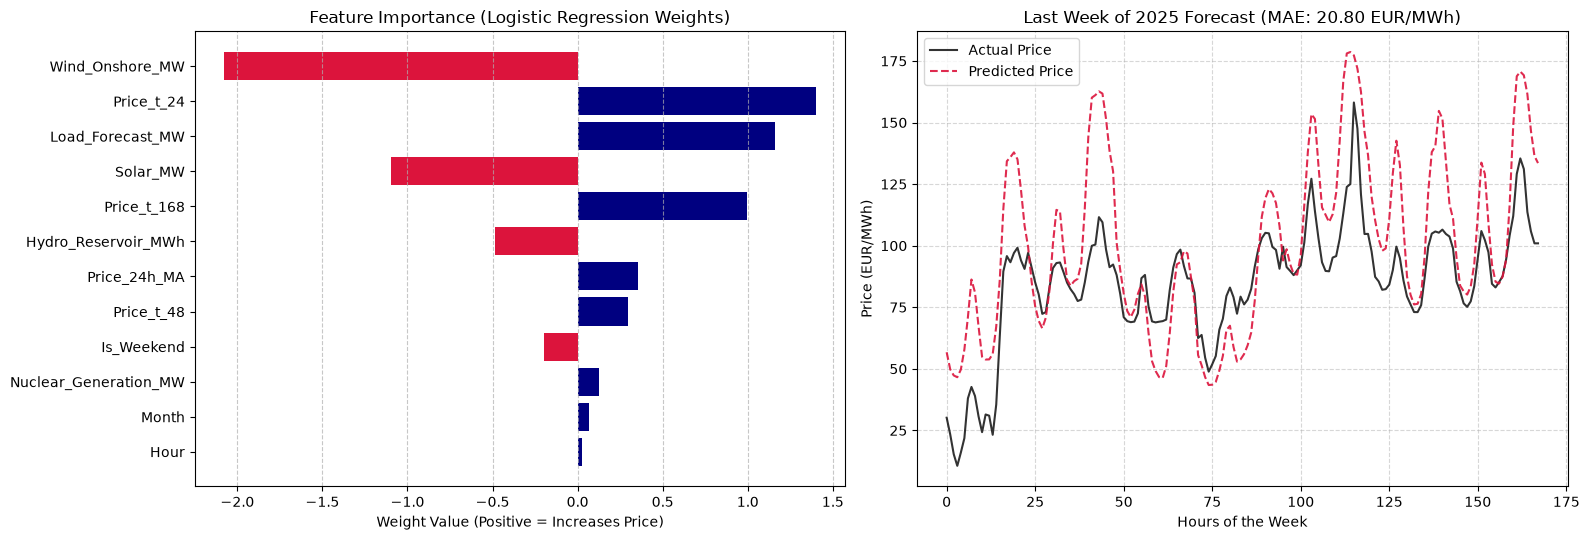

In [8]:
# 6 - Feature Importance and Test Week Visualization
feature_names = df.columns[2:].tolist()
weights_df = pd.DataFrame({"Feature": feature_names, "Weight": model_results["w"].flatten(), "Abs_Weight": np.abs(model_results["w"].flatten())})
weights_df = weights_df.sort_values(by="Abs_Weight", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1: Feature Importance
axes[0].barh(weights_df["Feature"][::-1], weights_df["Weight"][::-1], color=['crimson' if w < 0 else 'navy' for w in weights_df["Weight"][::-1]])
axes[0].set_title("Feature Importance (Logistic Regression Weights)")
axes[0].set_xlabel("Weight Value (Positive = Increases Price)")
axes[0].grid(axis="x", linestyle="--", alpha=0.7)

# Plot 2: Last Week Forecast
x_hours = np.arange(0, 168, 1)
axes[1].plot(x_hours, y_actual_week, label="Actual Price", color="black", lw=1.5, alpha=0.8)
axes[1].plot(x_hours, y_pred_week, label="Predicted Price", color="crimson", lw=1.5, alpha=0.9, linestyle="--")
axes[1].set_title(f"Last Week of 2025 Forecast (MAE: {mae_week:.2f} EUR/MWh)")
axes[1].set_xlabel("Hours of the Week")
axes[1].set_ylabel("Price (EUR/MWh)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 7 - Hyperparameter Optimization (Grid Search)
I AI MAXXED THIS PART so I want to review if it makes sense

Running Grid Search across 24 hyperparameter combinations...

 Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
         0.010         500    0.635559          84.45        82.39              44.91               50.79
         0.010        1000    0.618512          86.10        84.47              39.60               44.68
         0.010        2000    0.598095          88.35        87.29              32.41               36.83
         0.010        3000    0.587108          89.69        89.03              27.98               32.37
         0.025         500    0.615786          86.79        85.32              37.44               42.27
         0.025        1000    0.593510          89.10        88.26              29.93               34.29
         0.025        2000    0.577067          91.04        90.85              23.34               28.07
         0.025        3000    0.571279          91.75        91.84              20.82     

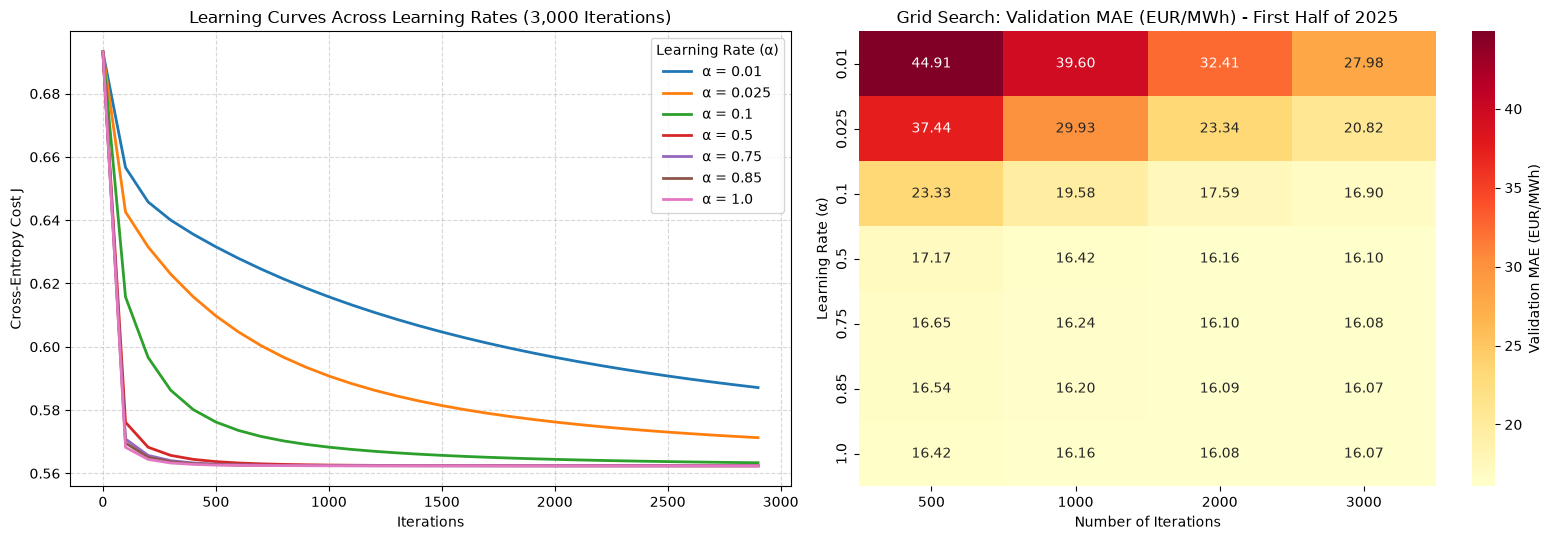

In [10]:
import seaborn as sns

# 1. Define Validation Set (First half of 2025 = first 4,380 hours)
val_hours = 4380
X_val_norm = test_set_x_normalized[:, :val_hours]
Y_val_norm = test_set_y_normalized[:, :val_hours]
y_val_orig = test_set_y_orig[:val_hours]

# 2. Define Hyperparameter Ranges for Grid Search
learning_rates = [0.01, 0.025, 0.1, 0.5, 0.75, 0.85, 1.0]
iterations_list = [500, 1000, 2000, 3000]

grid_results = []
curves_dict = {}


for lr in learning_rates:
    for n_iter in iterations_list:
        # Initialize and train model
        w_init, b_init = init_params(train_set_x_normalized.shape[0])
        params, _, costs = optimize(
            w_init, b_init,
            train_set_x_normalized, train_set_y_normalized,
            num_iterations=n_iter, learning_rate=lr, print_cost=False
        )
        
        # Save learning curve for the 3,000-iteration runs
        if n_iter == 3000:
            curves_dict[lr] = costs
            
        # Predictions on Train and Validation sets
        Y_pred_train = predict_continuous(params["w"], params["b"], train_set_x_normalized)
        Y_pred_val = predict_continuous(params["w"], params["b"], X_val_norm)
        
        # Normalized Accuracy (%)
        train_acc = 100.0 - np.mean(np.abs(Y_pred_train - train_set_y_normalized)) * 100.0
        val_acc = 100.0 - np.mean(np.abs(Y_pred_val - Y_val_norm)) * 100.0
        
        # Physical Scale Metrics (EUR/MWh) on Validation Set
        y_pred_val_eur = scaler_y_test.inverse_transform(Y_pred_val.T)
        val_mae = np.mean(np.abs(y_pred_val_eur - y_val_orig))
        val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))
        
        grid_results.append({
            "Learning_Rate": lr,
            "Iterations": n_iter,
            "Final_Cost": costs[-1],
            "Train_Acc (%)": round(train_acc, 2),
            "Val_Acc (%)": round(val_acc, 2),
            "Val_MAE (EUR/MWh)": round(val_mae, 2),
            "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
        })

# 3. Convert results to DataFrame and display best configuration
df_grid = pd.DataFrame(grid_results)
best_row = df_grid.loc[df_grid["Val_MAE (EUR/MWh)"].idxmin()]

print(df_grid.to_string(index=False))
print("\n" + "="*65)
print(f"BEST CONFIGURATION (Lowest Validation MAE):")
print(f"Learning Rate (α): {best_row['Learning_Rate']} | Iterations: {int(best_row['Iterations'])}")
print(f"Validation Accuracy: {best_row['Val_Acc (%)']:.2f}% | Validation MAE: {best_row['Val_MAE (EUR/MWh)']:.2f} EUR/MWh | Validation RMSE: {best_row['Val_RMSE (EUR/MWh)']:.2f} EUR/MWh")
print("="*65)

# 4. Visualization: Learning Curves by α and Grid Search Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Plot 1: Learning Curves for different learning rates
iters_x = np.arange(0, 3000, 100)
for lr, c_list in curves_dict.items():
    axes[0].plot(iters_x, c_list, lw=2, label=f"α = {lr}")
axes[0].set_title("Learning Curves Across Learning Rates (3,000 Iterations)")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel("Cross-Entropy Cost J")
axes[0].legend(title="Learning Rate (α)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Grid Search Heatmap (Validation MAE in EUR/MWh)
pivot_mae = df_grid.pivot(index="Learning_Rate", columns="Iterations", values="Val_MAE (EUR/MWh)")
sns.heatmap(pivot_mae, annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[1], cbar_kws={'label': 'Validation MAE (EUR/MWh)'})
axes[1].set_title("Grid Search: Validation MAE (EUR/MWh) - First Half of 2025")
axes[1].set_xlabel("Number of Iterations")
axes[1].set_ylabel("Learning Rate (α)")

plt.tight_layout()
plt.show()